# 01b · EAP-IG on edges

**Question:** which *connections* between components carry the sarcasm information, and how many are needed?

**Graph.** Senders write to the residual stream (the input embeddings, every attention head, every MLP);
receivers read from it (every attention block, every MLP block, the final answer). An edge `u → v` exists when
`u` writes before `v` reads. Senders are single heads; receivers are whole blocks (which head of a block reads an
edge is studied with path patching in Phase 3).

**Score (EAP-IG).** For every edge, the change in $d$ if `v` heard `u` from the clean instead of the corrupted
sentence, estimated with gradients averaged over `IG_STEPS` inputs between corrupted and clean, divided by
$d(S) - d(\text{corrupted})$ (same scale as $R$).

**Faithfulness.** We keep the top-$k$ edges, give every other edge its corrupted value (edge patching) and measure
$F = (d_{\text{circuit}} - d_{\text{corr}}) / (d_{\text{clean}} - d_{\text{corr}})$. We look for the smallest $k$ with
$F \ge 0.9$ in **both** experiments, and compare with random sets of edges of the same size.
These top-$k$ edges are the input of ACDC (Phase 2).

**Runtime:** T4 GPU. `MODEL = DEV_MODEL` (3B) first, then `MAIN_MODEL` (7B, about 30–40 min). Results are saved to Google Drive.

## Setup

In [1]:
import os, sys
REPO = "https://github.com/vasilis-pantzos/sarcasm-proposal.git"
ROOT = "/content/sarcasm-proposal"
if not os.path.exists(ROOT):
    !git clone -q {REPO} {ROOT}
else:
    !git -C {ROOT} pull -q
os.chdir(ROOT)
sys.path.insert(0, ROOT)
%pip install -q -U accelerate bitsandbytes

In [2]:
import os, json, time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr
from src.model import load_model, model_info, DEV_MODEL, MAIN_MODEL
from src.prompts import load_dataset, make_pairs, data_tag
from src.patching import score_pairs, keep_correct, mean_and_se
from src.eap import build_graph, eap_ig_over_pairs, CircuitEvaluator, top_k_mask, random_mask, edge_table, prune_dangling
from src.utils import mount_drive, results_dir, cached, set_seed

# ---------------- settings ----------------
MODEL = MAIN_MODEL          # DEV_MODEL (3B) for quick tests
DATA = "v2"                 # dataset version: "v1" (pilot) or "v2" (data/make_dataset_v2.py)
N_EAP_MAX = 200             # at most this many correct discovery pairs per experiment for EAP-IG
IG_STEPS = 5                # interpolation steps of integrated gradients
N_EVAL = 16                 # pairs per experiment used to measure faithfulness
K_GRID = [25, 50, 100, 200, 400, 800, 1600, 3200, 6400, 9600, 12800]
TARGET_F = 0.9
# ------------------------------------------
TAG_MODEL = MODEL.split("/")[-1]
TAG = TAG_MODEL + data_tag(DATA)           # v1 keeps the old folders
SUB = f"01b_eap_ig/{TAG}"
mount_drive()
print("results go to:", results_dir(SUB))
set_seed(0)

Mounted at /content/drive
results go to: /content/drive/MyDrive/sarcasm/01b_eap_ig/Qwen2.5-7B-Instruct_data-v2


In [3]:
t0 = time.time()
model, tok = load_model(MODEL)
INFO = model_info(model)
G = build_graph(model)
print(MODEL, INFO, f"loaded in {(time.time() - t0) / 60:.1f} min")
print(f"graph: {len(G.senders)} senders, {len(G.receivers)} receivers, {G.n_edges()} edges")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct {'n_layers': 28, 'n_heads': 28, 'n_kv_heads': 4, 'd_model': 3584, 'head_dim': 128} loaded in 1.6 min
graph: 813 senders, 57 receivers, 23577 edges


## Pairs (token-matched, discovery, answered correctly)

In [8]:
df = load_dataset(DATA)
PAIRS = {}
for e in ["situation", "phrase"]:
    ps = score_pairs(model, tok, make_pairs(df, tok, e))
    corr = keep_correct(ps)
    if DATA != "v1":      # v2 is ordered by situation pair: shuffle (seeded) so the pairs cover all situations
        orr = [corr[i] for i in np.random.default_rng(0).permutation(len(corr))]
    PAIRS[e] = corr[:N_EAP_MAX]
    print(f"{e:9s}: {len(corr)} of {len(ps)} pairs answered correctly, using {len(PAIRS[e])}")

situation: 615 of 630 pairs answered correctly, using 200
phrase   : 484 of 630 pairs answered correctly, using 200


## Sanity check: edge patching

All edges must give the clean answer, no edges the corrupted answer.

In [9]:
CHECKS = {}
for e in PAIRS:
    ev = CircuitEvaluator(model, tok, PAIRS[e][0], G)
    d_all, d_none = ev.d(G.valid), ev.d(np.zeros_like(G.valid))
    ok = abs(d_all - ev.d_clean) < 0.02 * abs(ev.d_clean - ev.d_corr) and abs(d_none - ev.d_corr) < 0.02 * abs(ev.d_clean - ev.d_corr)
    CHECKS[e] = ok
    print(f"{e:9s}: clean {ev.d_clean:+.3f} | all edges {d_all:+.3f} || corrupted {ev.d_corr:+.3f} | no edges {d_none:+.3f}  ->",
          "PASS" if ok else "FAIL")
    del ev; torch.cuda.empty_cache()
assert all(CHECKS.values()), "edge patching does not reproduce clean/corrupted: send this output to Claude"

situation: clean +15.875 | all edges +15.875 || corrupted -7.638 | no edges -7.638  -> PASS
phrase   : clean +15.875 | all edges +15.875 || corrupted +12.982 | no edges +12.982  -> PASS


## EAP-IG scores for every edge (cached)

In [10]:
gt0 = time.time()
SCORES = {e: cached(f"eap_ig_{e}_steps{IG_STEPS}", lambda e=e: eap_ig_over_pairs(model, tok, PAIRS[e], IG_STEPS), sub=SUB)
          for e in PAIRS}
print(f"done in {(time.time() - t0) / 60:.1f} min")
MEAN = {e: s.mean(0) for e, s in SCORES.items()}            # [S, V] per experiment
COMBINED = np.mean(list(MEAN.values()), axis=0)              # the circuit has to explain both experiments
np.savez_compressed(os.path.join(results_dir(SUB), "mean_scores.npz"), combined=COMBINED, **MEAN)

  20/200 pairs
  40/200 pairs
  60/200 pairs
  80/200 pairs
  100/200 pairs
  120/200 pairs
  140/200 pairs
  160/200 pairs
  180/200 pairs
  200/200 pairs
[saved]  /content/drive/MyDrive/sarcasm/01b_eap_ig/Qwen2.5-7B-Instruct_data-v2/eap_ig_situation_steps5.pt
  20/200 pairs
  40/200 pairs
  60/200 pairs
  80/200 pairs
  100/200 pairs
  120/200 pairs
  140/200 pairs
  160/200 pairs
  180/200 pairs
  200/200 pairs
[saved]  /content/drive/MyDrive/sarcasm/01b_eap_ig/Qwen2.5-7B-Instruct_data-v2/eap_ig_phrase_steps5.pt
done in 11.6 min


### Where are the important edges?

Sum of $|\text{score}|$ from the senders of each layer (rows) to each receiver (columns).

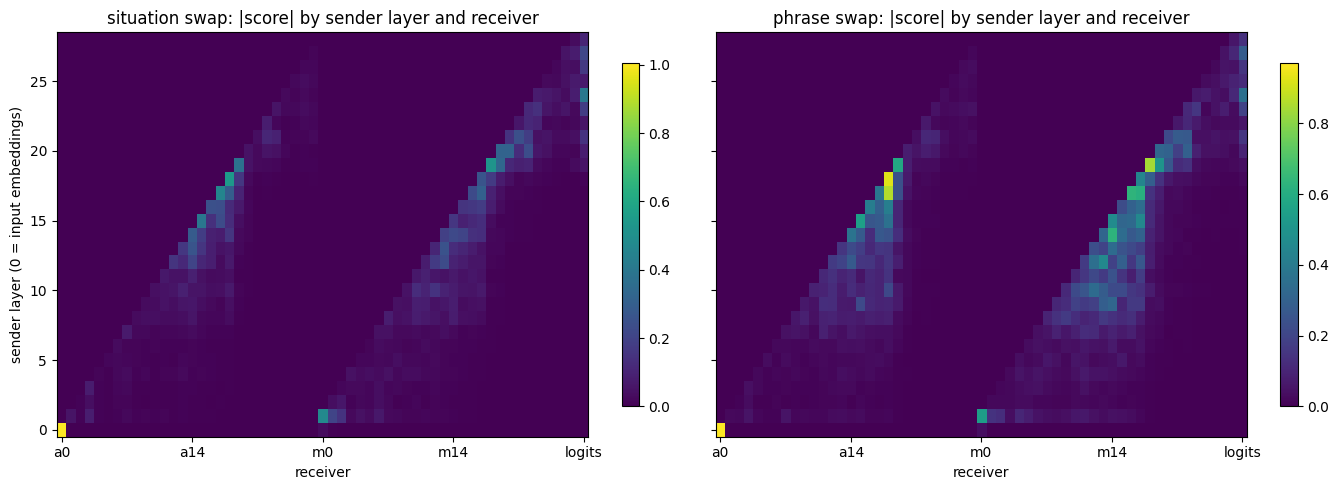

top 25 edges (combined score):


,sender,receiver,score_situation,score_phrase,combined
0,input,a0,1.0062,0.9712,0.9887
1,m17,a18,0.3184,0.5726,0.4455
2,m23,logits,0.3054,0.2750,0.2902
3,m16,a18,0.1348,0.2442,0.1895
4,m18,m19,0.1053,0.2674,0.1864
5,m19,m22,0.1610,0.2033,0.1822
6,m19,m20,0.2002,0.1564,0.1783
7,m18,a19,0.1246,0.1998,0.1622
8,a18.h4,m18,0.1624,0.1567,0.1595
9,m14,a15,0.1208,0.1938,0.1573


In [11]:
L = G.n_layers
def sender_layer(i):
    if i == 0: return 0
    if i <= L * G.n_heads: return 1 + (i - 1) // G.n_heads
    return 1 + (i - 1 - L * G.n_heads)
rows = np.array([sender_layer(i) for i in range(len(G.senders))])   # 0 = input, 1.. = layer 0..
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (e, m) in zip(axes, MEAN.items()):
    agg = np.zeros((L + 1, len(G.receivers)))
    np.add.at(agg, rows, np.abs(m))
    im = ax.imshow(agg, aspect="auto", origin="lower", cmap="viridis")
    ax.set_xticks([0, L // 2, L, L + L // 2, 2 * L]); ax.set_xticklabels(["a0", f"a{L//2}", "m0", f"m{L//2}", "logits"])
    ax.set_xlabel("receiver"); ax.set_title(f"{e} swap: |score| by sender layer and receiver")
    plt.colorbar(im, ax=ax, shrink=0.85)
axes[0].set_ylabel("sender layer (0 = input embeddings)")
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "edges_by_layer.png"), dpi=150); plt.show()

TABLE = edge_table(MEAN, G)
print("top 25 edges (combined score):")
display(TABLE.head(25).round(4))

## Faithfulness of the top-$k$ edges

For each $k$: top-$k$ edges by combined $|\text{score}|$ vs $k$ random edges, on `N_EVAL` pairs per experiment.

**Dangling edges.** An edge helps only if it lies on a path *input → … → logits* inside the circuit: an edge
whose sender gets no clean information, or whose receiver reaches the answer through no circuit edge, carries
exactly zero change. `prune_dangling` removes them; the faithfulness stays the same, the circuit gets smaller.
The column `edges_after_pruning` is the real size of each top-$k$ circuit.

[cached] /content/drive/MyDrive/sarcasm/01b_eap_ig/Qwen2.5-7B-Instruct_data-v2/faithfulness_situation_16pairs_kmax12800.pt
[cached] /content/drive/MyDrive/sarcasm/01b_eap_ig/Qwen2.5-7B-Instruct_data-v2/faithfulness_phrase_16pairs_kmax12800.pt
done in 0.0 min


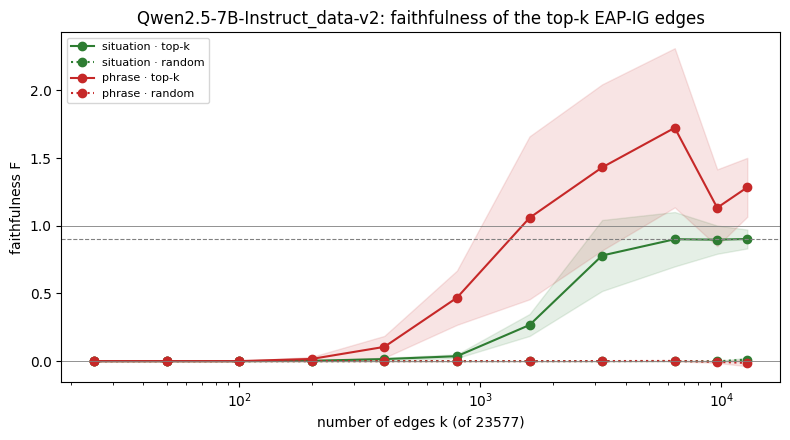

,k,edges_after_pruning,F_situation_top,F_situation_random,F_phrase_top,F_phrase_random
0,25,0,0.000,0.000,0.000,0.000
1,50,0,0.000,0.000,0.000,0.000
2,100,0,0.000,0.000,0.000,0.000
3,200,178,0.003,-0.000,0.016,-0.000
4,400,371,0.015,-0.000,0.105,0.000
5,800,781,0.036,-0.000,0.468,0.000
6,1600,1573,0.267,-0.000,1.059,-0.000
7,3200,3200,0.780,-0.000,1.432,0.000
8,6400,6400,0.901,0.001,1.724,0.001
9,9600,9600,0.897,-0.001,1.133,-0.005


situation: smallest k with F >= 0.9: 6400 (6400 edges after pruning)
phrase   : smallest k with F >= 0.9: 1600 (1573 edges after pruning)
K_STAR set to 9600 (phrase overshoots at 6400)

smallest k with F >= 0.9 in both experiments: 9600, 9600 edges after pruning


In [16]:
def faith_curve(e):
    rng = np.random.default_rng(0)
    top, rnd = [], []
    for p in PAIRS[e][:N_EVAL]:
        ev = CircuitEvaluator(model, tok, p, G)
        top.append([ev.faithfulness(top_k_mask(COMBINED, G, k)) for k in K_GRID])
        rnd.append([ev.faithfulness(random_mask(G, k, rng)) for k in K_GRID])
        del ev; torch.cuda.empty_cache()
    return dict(top=np.array(top), random=np.array(rnd))

t0 = time.time()
FAITH = {e: cached(f"faithfulness_{e}_{N_EVAL}pairs_kmax{K_GRID[-1]}", lambda e=e: faith_curve(e), sub=SUB) for e in PAIRS}
PRUNED = {k: int(prune_dangling(top_k_mask(COMBINED, G, k), G).sum()) for k in K_GRID}
print(f"done in {(time.time() - t0) / 60:.1f} min")

fig, ax = plt.subplots(figsize=(8, 4.5))
cols = {"situation": "#2E7D32", "phrase": "#C62828"}
for e, f in FAITH.items():
    for kind, ls in [("top", "-"), ("random", ":")]:
        m, se = mean_and_se(f[kind])
        ax.plot(K_GRID, m, ls, marker="o", color=cols[e], label=f"{e} · {'top-k' if kind == 'top' else 'random'}")
        ax.fill_between(K_GRID, m - 1.96 * se, m + 1.96 * se, color=cols[e], alpha=0.12)
ax.axhline(TARGET_F, c="gray", ls="--", lw=0.8); ax.axhline(1, c="gray", lw=0.6); ax.axhline(0, c="gray", lw=0.6)
ax.set_xscale("log"); ax.set_xlabel(f"number of edges k (of {G.n_edges()})"); ax.set_ylabel("faithfulness F")
ax.legend(fontsize=8); ax.set_title(f"{TAG}: faithfulness of the top-k EAP-IG edges")
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "faithfulness.png"), dpi=150); plt.show()

curve = pd.DataFrame({"k": K_GRID, "edges_after_pruning": [PRUNED[k] for k in K_GRID], **{f"F_{e}_{kind}": FAITH[e][kind].mean(0) for e in FAITH for kind in ["top", "random"]}})
display(curve.round(3))
for e in FAITH:
    ok_e = [k for k in K_GRID if FAITH[e]["top"].mean(0)[K_GRID.index(k)] >= TARGET_F]
    print(f"{e:9s}: smallest k with F >= {TARGET_F}: " + (f"{ok_e[0]} ({PRUNED[ok_e[0]]} edges after pruning)" if ok_e else "not reached"))
ok = [k for k in K_GRID if all(FAITH[e]["top"].mean(0)[K_GRID.index(k)] >= TARGET_F for e in FAITH)]
K_STAR = 9600; print("K_STAR set to", K_STAR, "(phrase overshoots at 6400)")
print(f"\nsmallest k with F >= {TARGET_F} in both experiments: {K_STAR}, {PRUNED[K_STAR]} edges after pruning" + ("" if ok else "  (target not reached: using the largest k)"))

## Consistency with Phase 1a (heads that matter there should matter here)

In [17]:
path_1a = os.path.join(results_dir(f"01a_head_attribution/{TAG_MODEL}"), "head_scores.csv")   # 1a: v1 data
if os.path.exists(path_1a):
    h1a = pd.read_csv(path_1a).groupby(["layer", "head"]).est_R.sum()      # summed over regions and experiments
    eap_head = np.abs(COMBINED[1:1 + L * G.n_heads]).sum(1)                 # total |score| of each head's outgoing edges
    a = np.array([h1a.get((l, h), 0.0) for l in range(L) for h in range(G.n_heads)])
    rho = spearmanr(np.abs(a), eap_head).correlation
    print(f"Spearman correlation of head importance, Phase 1a vs EAP-IG: {rho:.2f}")
else:
    print("Phase 1a results for this model not found on Drive:", path_1a)

Spearman correlation of head importance, Phase 1a vs EAP-IG: 0.67


## The candidate circuit: strongest edges

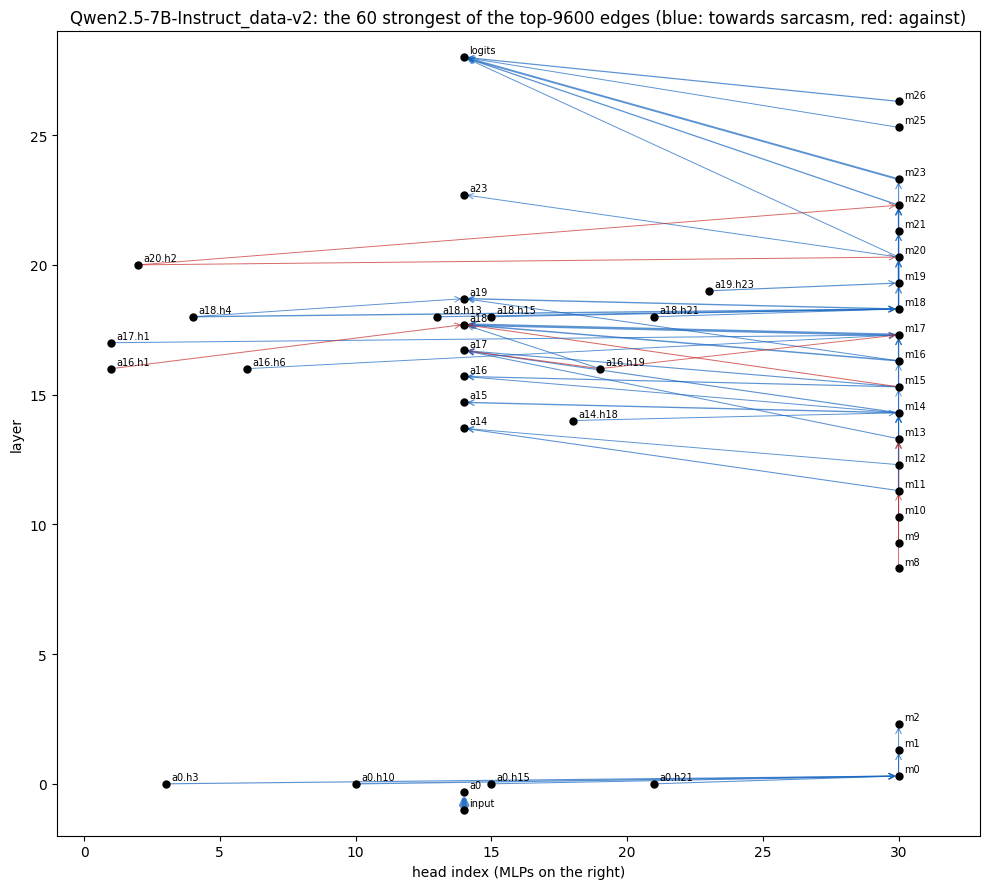

In [18]:
def draw(mask, scores, n_max=60, title=""):
    # positions: x = head index (input in the middle, MLPs on the right), y = layer
    H = G.n_heads
    def pos(name, recv=False):
        if name == "input": return (H / 2, -1)
        if name == "logits": return (H / 2, L)
        if name.startswith("a") and "." in name:
            l, h = name[1:].split(".h"); return (int(h), int(l))
        if name.startswith("a"): return (H / 2, int(name[1:]) - 0.3)       # attention block as receiver
        return (H + 2, int(name[1:]) + 0.3)                                # MLP
    tab = edge_table({"s": scores}, G, mask).head(n_max)
    lim = np.abs(tab["combined"]).max()
    fig, ax = plt.subplots(figsize=(10, 9))
    for _, r in tab.iterrows():
        (x0, y0), (x1, y1) = pos(r.sender), pos(r.receiver, True)
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="->", color="#1565C0" if r.combined > 0 else "#C62828",
                                    lw=0.5 + 3 * abs(r.combined) / lim, alpha=0.7))
    nodes = set(tab.sender) | set(tab.receiver)
    for n in nodes:
        x, y = pos(n)
        ax.scatter(x, y, s=25, c="black", zorder=3)
        ax.text(x + 0.2, y + 0.15, n, fontsize=7)
    ax.set_xlim(-1, H + 5); ax.set_ylim(-2, L + 1)
    ax.set_xlabel("head index (MLPs on the right)"); ax.set_ylabel("layer")
    ax.set_title(title)
    plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "circuit_top_edges.png"), dpi=150); plt.show()

draw(prune_dangling(top_k_mask(COMBINED, G, K_STAR), G), COMBINED, n_max=60,
     title=f"{TAG}: the 60 strongest of the top-{K_STAR} edges (blue: towards sarcasm, red: against)")

## Save for ACDC (Phase 2)

In [19]:
mask = prune_dangling(top_k_mask(COMBINED, G, K_STAR), G)
edges = edge_table(MEAN, G, mask)
edges.to_csv(os.path.join(results_dir(SUB), f"candidate_edges_top{K_STAR}.csv"), index=False)
np.save(os.path.join(results_dir(SUB), "candidate_mask.npy"), mask)
curve.to_csv(os.path.join(results_dir(SUB), "faithfulness_curve.csv"), index=False)
json.dump(dict(model=MODEL, k_star=K_STAR, n_candidate_edges=int(mask.sum()), n_edges=G.n_edges(), ig_steps=IG_STEPS, n_eval=N_EVAL, data=DATA, n_eap_pairs={e: len(PAIRS[e]) for e in PAIRS},
               n_pairs={e: len(p) for e, p in PAIRS.items()}),
          open(os.path.join(results_dir(SUB), "summary.json"), "w"), indent=1)
print(f"saved {len(edges)} candidate edges (top-{K_STAR}, pruned) to", results_dir(SUB))

saved 9600 candidate edges (top-9600, pruned) to /content/drive/MyDrive/sarcasm/01b_eap_ig/Qwen2.5-7B-Instruct_data-v2
